# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

brut = pd.read_csv("donnees/consommation_brut.csv")
print("Forme :", brut.shape)
print()
print(brut.dtypes)
print()
print("Valeurs manquantes :")
print(brut.isna().sum())
print()
print("Lignes en double :", brut.duplicated().sum())

Forme : (300, 4)

mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

Valeurs manquantes :
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

Lignes en double : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [18]:
print("Écritures différentes :", brut["quartier"].nunique())
brut["quartier"].unique()

Écritures différentes : 43


<ArrowStringArray>
[   'Bas-Peu-de-Chose',    'bas-peu-de-chose',   'Bas-Peu-de-Chose ',
   ' Bas-Peu-de-Chose',    'BAS-PEU-DE-CHOSE',          'BOIS-VERNA',
          'Bois-Verna',        'Centre-ville',        'centre-ville',
       'Centre-ville ',        'CENTRE-VILLE',           'Delmas 33',
          'Delmas 33 ',          ' Delmas 33',           'DELMAS 33',
           'Delmas 65',          ' Delmas 65',           'delmas 65',
           'Delmas 75',           'delmas 75',          'Delmas 75 ',
          ' Delmas 75',           'Thomassin',          'Thomassin ',
          ' Thomassin',           'THOMASSIN',  'Place Saint-Pierre',
  'PLACE SAINT-PIERRE', 'Place Saint-Pierre ',  'place saint-pierre',
 ' Place Saint-Pierre',      'Morne Calvaire',     ' Morne Calvaire',
            'Carénage',           'Carénage ',            'CARÉNAGE',
            'carénage',           ' Carénage',              'Rue 15',
             'Rue 15 ',              'RUE 15',         'Petite-Anse',
 

**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [19]:
# Ce que pd.to_numeric ne sait pas convertir, sans compter les vrais manquants
converti = pd.to_numeric(brut["kwh"], errors="coerce")
pas_nombre = converti.isna() & brut["kwh"].notna()
print(pas_nombre.sum(), "valeurs non convertibles")
brut.loc[pas_nombre, "kwh"].head(10)

52 valeurs non convertibles


0     184410 kWh
4     206280 kWh
9     215140 kWh
13       251 900
21    274520 kWh
27    301740 kWh
36    233010 kWh
43    155930 kWh
51    212510 kWh
53    424110 kWh
Name: kwh, dtype: str

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [20]:
propre = brut.copy()

# On retire « kWh » et les espaces, puis on convertit
propre["kwh"] = propre["kwh"].str.replace("kWh", "").str.replace(" ", "")
propre["kwh"] = pd.to_numeric(propre["kwh"])

print("Manquants dans kwh :", propre["kwh"].isna().sum())

Manquants dans kwh : 9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [21]:
quartiers = pd.read_csv("donnees/quartiers.csv")

# Dictionnaire : nom en minuscules -> nom officiel
noms = dict(zip(quartiers["quartier"].str.lower(), quartiers["quartier"]))

propre["quartier"] = propre["quartier"].str.strip().str.lower().map(noms)

print("Quartiers :", propre["quartier"].nunique())
print("Noms perdus par map :", propre["quartier"].isna().sum())

Quartiers : 12
Noms perdus par map : 0


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [22]:
print("Avant :", propre.shape)
propre = propre.drop_duplicates()
print("Sans doublons :", propre.shape)
propre = propre.dropna(subset=["kwh"])
print("Sans kwh manquant :", propre.shape)

Avant : (300, 4)
Sans doublons : (288, 4)
Sans kwh manquant : (279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [23]:
# Médiane de chaque quartier, recopiée sur chaque ligne
mediane = propre.groupby("quartier")["kwh"].transform("median")
trop_grand = propre["kwh"] > 3 * mediane

print(trop_grand.sum(), "relevés trop grands :")
print(propre[trop_grand])

propre.loc[trop_grand, "kwh"] = propre.loc[trop_grand, "kwh"] / 10
propre["kwh"] = propre["kwh"].astype(int)

print()
print("Maximum de kwh :", propre["kwh"].max())

4 relevés trop grands :
        mois        quartier        kwh  heures_courant
90   2025-02       Delmas 33  3602600.0            10.1
140  2025-02       Delmas 75  2012700.0            11.1
200  2024-02  Morne Calvaire  1439200.0            11.4
251  2024-01          Rue 15   997700.0             5.9

Maximum de kwh : 742780


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [24]:
ref = pd.read_csv("donnees/consommation.csv")

# Mêmes lignes (les mois et quartiers gardés dans propre) et mêmes colonnes
ref_memes = ref.merge(propre[["mois", "quartier"]], on=["mois", "quartier"])[propre.columns]

a = propre.sort_values(["quartier", "mois"]).reset_index(drop=True)
b = ref_memes.sort_values(["quartier", "mois"]).reset_index(drop=True)
print(propre.shape)
a.equals(b)

(279, 4)


True

## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [25]:
print("Avant :", len(propre))
avec_quartiers = propre.merge(quartiers, on="quartier", how="left")
print("Après :", len(avec_quartiers))

avec_quartiers["kwh_par_abonne"] = (avec_quartiers["kwh"] / avec_quartiers["abonnes"]).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4].astype(int)

avec_quartiers[(avec_quartiers["quartier"] == "Bas-Peu-de-Chose") & (avec_quartiers["mois"] == "2024-01")]

Avant : 279
Après : 279


,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee
0,2024-01,Bas-Peu-de-Chose,184410,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [26]:
meteo = pd.read_csv("donnees/meteo.csv")

print("Avant :", len(avec_quartiers))
avec_meteo = avec_quartiers.merge(meteo, on=["mois", "commune"], how="left")
print("Après :", len(avec_meteo))
print("Températures manquantes :", avec_meteo["temperature_c"].isna().sum())

Avant : 279
Après : 279
Températures manquantes : 0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [27]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)

df = pd.read_csv("donnees/consommation_propre.csv")
print(df.shape)
df.head()

(279, 11)


,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee,temperature_c,pluie_mm
0,2024-01,Bas-Peu-de-Chose,184410,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024,25.7,33
1,2024-02,Bas-Peu-de-Chose,195930,11.9,Port-au-Prince,Résidentiel,2150,91.1,2024,25.5,40
2,2024-03,Bas-Peu-de-Chose,186560,10.2,Port-au-Prince,Résidentiel,2150,86.8,2024,27.2,99
3,2024-04,Bas-Peu-de-Chose,236730,12.2,Port-au-Prince,Résidentiel,2150,110.1,2024,27.4,119
4,2024-05,Bas-Peu-de-Chose,206280,10.2,Port-au-Prince,Résidentiel,2150,95.9,2024,28.1,185


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [28]:
print("Par type de quartier :")
print(df.groupby("type")["kwh_par_abonne"].mean().round(1))
print()
print("Classement des 12 quartiers :")
classement = df.groupby("quartier")["kwh_par_abonne"].mean().round(1).sort_values(ascending=False)
classement

Par type de quartier :
type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

Classement des 12 quartiers :


quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64

**Ce qu'on en conclut :** un abonné d'un quartier commercial consomme en moyenne 393.2 kWh par mois, plus de trois fois plus qu'un abonné résidentiel (117.4 kWh). Les trois premiers du classement sont des quartiers commerciaux : Centre-ville (468.7), Place Saint-Pierre (458.3) et Delmas 33 (374.4).

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

annee            2024   2025  hausse_%
commune                               
Cap-Haïtien      4.59   5.62      22.5
Pétion-Ville     8.60   9.68      12.6
Port-au-Prince  10.09  10.31       2.3
Delmas          11.61  11.74       1.1


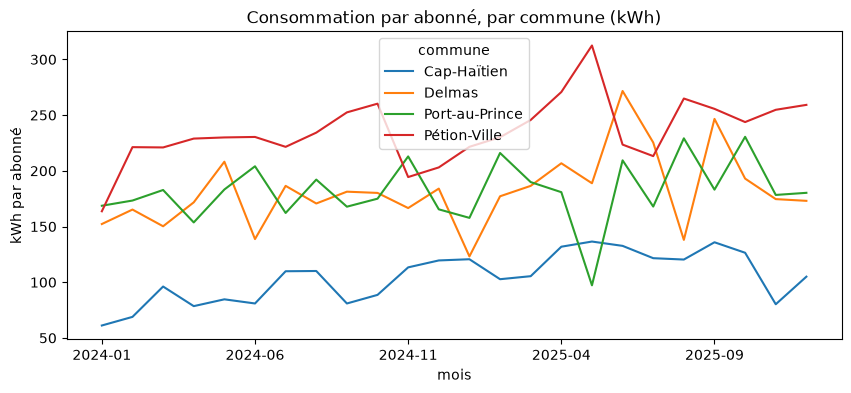

In [29]:
tableau = df.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")

# Hausse en %, calculée avant d'arrondir
tableau["hausse_%"] = ((tableau[2025] / tableau[2024] - 1) * 100).round(1)

# Totaux en millions de kWh
tableau[[2024, 2025]] = (tableau[[2024, 2025]] / 1_000_000).round(2)
print(tableau.sort_values("hausse_%", ascending=False))

# Courbe de la consommation par abonné, mois par mois, pour chaque commune
par_mois = df.groupby(["mois", "commune"])["kwh"].sum() / df.groupby(["mois", "commune"])["abonnes"].sum()
par_mois.unstack().plot(figsize=(10, 4), title="Consommation par abonné, par commune (kWh)")
plt.ylabel("kWh par abonné")
plt.show()

**Ce qu'on en conclut :** Cap-Haïtien est la commune qui consomme le moins, mais c'est elle qui progresse le plus : de 4.59 à 5.62 millions de kWh, soit +22.5 % (22.46 % avant arrondi, l'énoncé indique 22.4). Pétion-Ville suit avec +12.6 %, tandis que Delmas, la plus grosse consommatrice, est presque stable (+1.1 %).

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

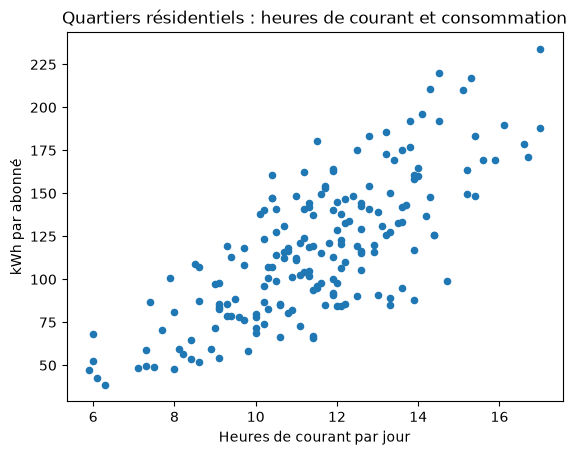

Corrélation avec les heures de courant : 0.76
Corrélation avec la température : -0.15


In [30]:
residentiel = df[df["type"] == "Résidentiel"]

residentiel.plot.scatter(x="heures_courant", y="kwh_par_abonne",
                         title="Quartiers résidentiels : heures de courant et consommation")
plt.xlabel("Heures de courant par jour")
plt.ylabel("kWh par abonné")
plt.show()

print("Corrélation avec les heures de courant :", round(residentiel["kwh_par_abonne"].corr(residentiel["heures_courant"]), 2))
print("Corrélation avec la température :", round(residentiel["kwh_par_abonne"].corr(residentiel["temperature_c"]), 2))

**Ce qu'on en conclut :** dans les quartiers résidentiels, la consommation par abonné suit les heures de courant (corrélation de 0.76, forte et positive) : plus il y a de courant, plus on consomme. Elle ne suit pas la chaleur (corrélation de -0.15, très faible).

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

                  Q1  médiane     Q3
commune                             
Cap-Haïtien      8.3     10.0  11.70
Delmas          10.1     11.9  13.00
Port-au-Prince  10.7     11.6  13.10
Pétion-Ville    10.4     11.6  13.05


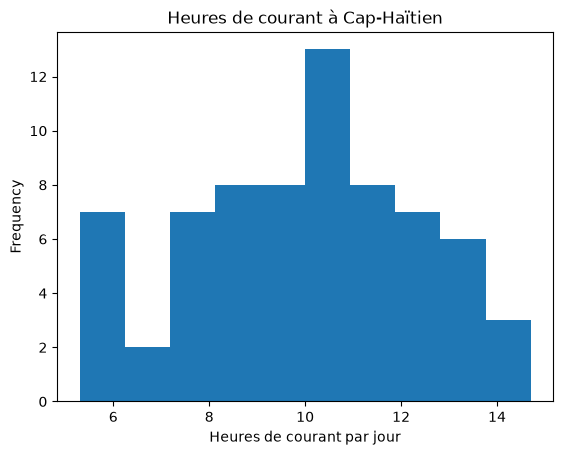

3 relevés de 2025 sous 8 heures :


,mois,quartier,heures_courant
81,2025-01,Delmas 33,7.4
227,2025-08,Carénage,7.3
253,2025-11,Rue 15,5.9


In [31]:
print(df.groupby("commune")["heures_courant"].quantile([0.25, 0.5, 0.75]).unstack().rename(columns={0.25: "Q1", 0.5: "médiane", 0.75: "Q3"}))

df[df["commune"] == "Cap-Haïtien"]["heures_courant"].plot.hist(bins=10, title="Heures de courant à Cap-Haïtien")
plt.xlabel("Heures de courant par jour")
plt.show()

moins_de_8 = df[(df["annee"] == 2025) & (df["heures_courant"] < 8)]
print(len(moins_de_8), "relevés de 2025 sous 8 heures :")
moins_de_8[["mois", "quartier", "heures_courant"]]

**Ce qu'on en conclut :** les coupures sont les plus longues à Cap-Haïtien, avec une médiane de 10.0 heures de courant par jour, contre 11.6 à 11.9 heures dans les autres communes. En 2025, seuls 3 relevés passent sous 8 heures : à Carénage, Delmas 33 et Rue 15.

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [32]:
df.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]

,mois,quartier,type,kwh
87,2025-07,Delmas 33,Commercial,742780
56,2024-11,Centre-ville,Commercial,597730
88,2025-09,Delmas 33,Commercial,591420


**Ce qu'on en conclut :** les trois plus grosses consommations viennent de quartiers commerciaux : Delmas 33 en juillet 2025 (742 780 kWh), Centre-ville en novembre 2024 (597 730 kWh) et Delmas 33 en septembre 2025 (591 420 kWh). Ce sont des valeurs réelles, pas des erreurs : les relevés 10 fois trop grands ont été corrigés à la question 7.

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

**Réponse au directeur :** la consommation suit les heures de courant, pas la chaleur. Dans les quartiers résidentiels, la consommation par abonné a une corrélation de 0.76 avec les heures de courant, contre -0.15 avec la température. Mais une corrélation ne prouve pas une cause : elle montre que les deux varient ensemble, pas que plus de courant fait consommer plus, et d'autres facteurs (saison, activité, nombre d'appareils) peuvent jouer.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.